# Customer Segmentation Analysis

This notebook performs **customer segmentation using K-Means clustering** on customer marketing data.

## Project Objectives
- Understand the structure and quality of the customer dataset.
- Clean missing values, invalid records, and outliers.
- Create useful customer-level features such as **Age, TotalSpend, TotalPurchases, Children**, and **TotalCampaignAccepted**.
- Standardize selected numerical features before clustering.
- Compare different values of **K** using the Elbow Method and Silhouette Score.
- Build customer segments using **K-Means clustering**.
- Profile and visualize the final customer segments.

> **Note:** Explanations are written in simple English so that each step can be easily understood and presented during a project viva or presentation.


## Project Navigation — Where are the 5 Models?

If your requirement is specifically **“5 Model Building + Model Evaluation”**, go directly to:

- **Section 9.1:** Model 1 — K-Means
- **Section 9.2:** Model 2 — Agglomerative Hierarchical Clustering
- **Section 9.3:** Model 3 — Gaussian Mixture Model (GMM)
- **Section 9.4:** Model 4 — BIRCH
- **Section 9.5:** Model 5 — DBSCAN
- **Section 10:** Evaluation of all five models
- **Section 10.1:** Five-model evaluation table
- **Section 10.2:** Model ranking
- **Section 10.3:** Evaluation charts
- **Section 10.4:** Evaluation interpretation

All explanations are written in English and the code cells include comments for easier understanding.


## 1. Setup and Library Installation

Import the libraries required for data loading, analysis, visualization, and machine learning.


In [1]:
# Install the required Python libraries for data analysis, visualization, Excel files, and machine learning.
# Remove the leading ! if running this command outside Jupyter.

# !pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [2]:
# Import pandas for working with tabular data.
# Import numpy for numerical operations.
# Import matplotlib and seaborn for data visualization.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Dataset

Load the Excel dataset and perform an initial inspection of the customer records.


In [3]:
# Load the customer marketing dataset from an Excel file into a pandas DataFrame.
# head() displays the first five rows so we can quickly inspect the data.

df = pd.read_excel("marketing_campaign.xlsx")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


## 3. Dataset Structure and Data Quality

The following checks help us understand the size, columns, data types, missing values, duplicates, and unique values in the dataset.


In [4]:
# Check the number of rows and columns in the dataset.
# The output is returned as: (number_of_rows, number_of_columns).

df.shape

(2240, 29)

In [5]:
# Check the total number of individual values in the DataFrame.
# It is equal to rows multiplied by columns.

df.size

64960

In [6]:
# Display column names, data types, non-null counts, and memory usage.
# This is useful for understanding the structure and data quality.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   object        
 3   Marital_Status       2240 non-null   object        
 4   Income               2216 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[ns]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-nul

In [7]:
# Display all column names available in the dataset.

df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [8]:
# Generate descriptive statistics for numerical columns.
# This includes count, mean, standard deviation, minimum, quartiles, and maximum.

df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,2013-07-10 10:01:42.857142784,49.109375,303.935714,26.302232,166.950000,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,23.750000,1.000000,16.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,173.500000,8.000000,67.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.250000,33.000000,232.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,NaN,28.962453,336.597393,39.773434,225.715373,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274


In [9]:
# Count missing values in every column.
# A value greater than 0 means that the column contains missing data.

df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [10]:
# Count duplicate rows in the dataset.
# Duplicate records can affect the quality of customer segmentation.

df.duplicated().sum()

np.int64(0)

In [11]:
# Count the number of unique values in each column.
# This helps identify constant columns and understand categorical/binary variables.

df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [12]:
# Find columns that contain only one unique value.
# Such columns do not provide useful information for clustering.

constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

constant_columns

['Z_CostContact', 'Z_Revenue']

In [13]:
# Remove constant columns because they do not help distinguish customers.

df = df.drop(columns=["Z_CostContact", "Z_Revenue"])

## 4. Data Cleaning and Feature Preparation

Before clustering, we identify unrealistic values and create meaningful customer-level features.


In [14]:
# Inspect the statistical distribution of Year_Birth.
# This helps us identify unusual or unrealistic birth years before creating Age.

df["Year_Birth"].describe()

count    2240.000000
mean     1968.805804
std        11.984069
min      1893.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64

In [15]:
# Create a new Age feature using the current project year (2026) minus the customer's birth year.

df["Age"] = 2026 - df["Year_Birth"]

In [16]:
# Display the first few Age values to verify that the new feature was created correctly.

df["Age"].head()

0    69
1    72
2    61
3    42
4    45
Name: Age, dtype: int64

In [17]:
# Create a mask for unrealistic ages below 18 or above 100.
# Replace those invalid Age values with NaN so they can be handled during data cleaning.

# Create a Boolean mask for unrealistic ages below 18 or above 100.
# Invalid ages are replaced with NaN so they can be imputed later.
invalid_age_mask = (df["Age"] < 18) | (df["Age"] > 100)
df.loc[invalid_age_mask, "Age"] = np.nan

# Count how many invalid age records were found.
Invalid_Age = invalid_age_mask.sum()

In [18]:
# Display the number of invalid age records identified above.

# Display the number of invalid age records that were replaced with NaN.
Invalid_Age

np.int64(3)

In [19]:
# Replace missing Income values with the median Income.
# Replace missing Age values with the median Age.
# Median imputation is less sensitive to extreme values than mean imputation.

df["Income"] = df["Income"].fillna(df["Income"].median())

df["Age"] = df["Age"].fillna(df["Age"].median())

### Distribution Check: Age and Income

Histograms help us understand how customer **Age** and **Income** are distributed.  
They are useful for spotting skewness, concentration, and unusual values before modeling.


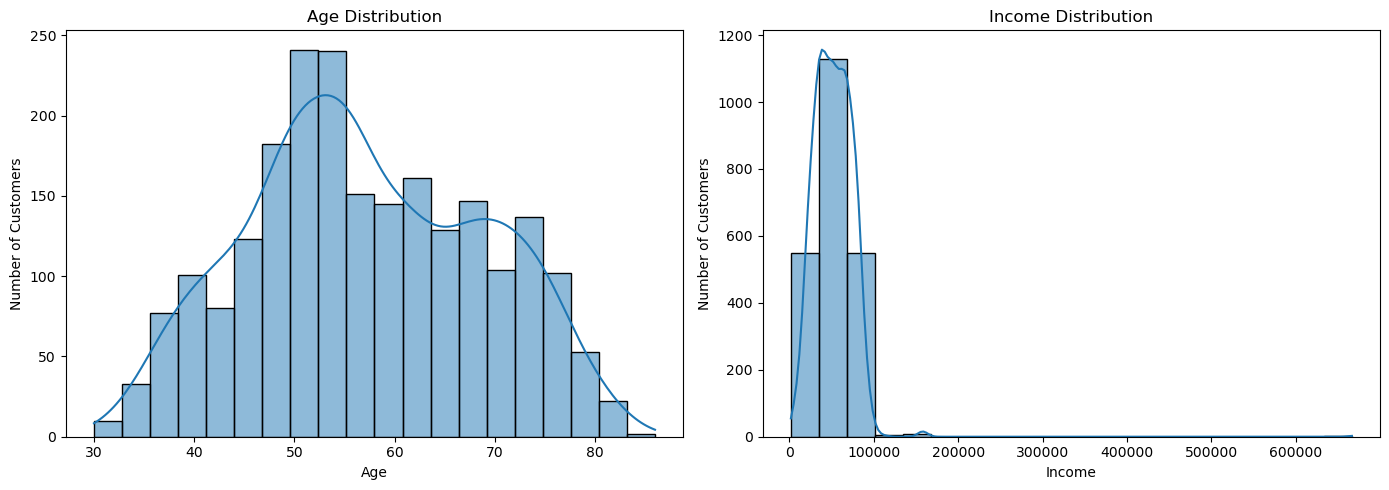

In [20]:
# Plot the distributions of Age and Income.
# Histograms show how frequently values occur within different ranges.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Age"], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Customers")

sns.histplot(df["Income"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Income Distribution")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


### Feature Engineering: Spending Behaviour

Combine product-wise spending into a single **TotalSpend** feature.


In [21]:
# List all product spending columns.
# Add spending across these product categories to create TotalSpend for each customer.

spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["TotalSpend"] = df[spending_columns].sum(axis=1)

In [22]:
# Display TotalSpend for all customers.

df["TotalSpend"]

0       1617
1         27
2        776
3         53
4        422
        ... 
2235    1341
2236     444
2237    1241
2238     843
2239     172
Name: TotalSpend, Length: 2240, dtype: int64

### Distribution Check: Total Spending

The **TotalSpend** histogram shows how much customers spend across all product categories.


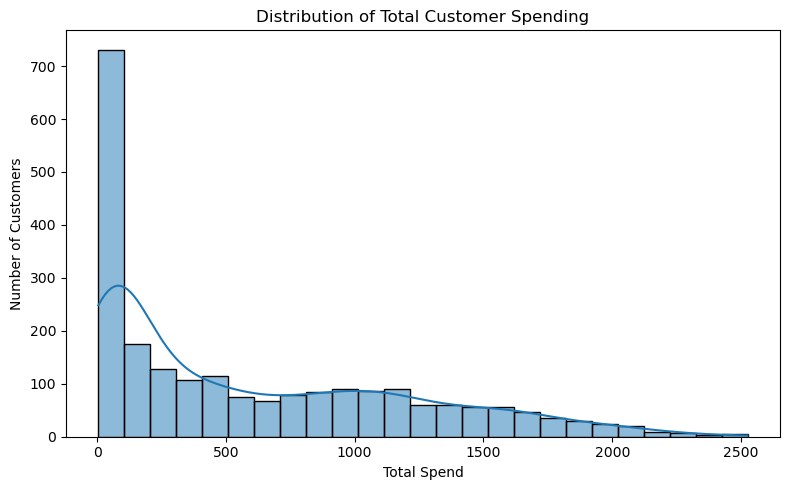

In [23]:
# Plot the distribution of TotalSpend.
# This helps us understand the typical spending range and whether the data is skewed.

plt.figure(figsize=(8, 5))
sns.histplot(df["TotalSpend"], bins=25, kde=True)
plt.title("Distribution of Total Customer Spending")
plt.xlabel("Total Spend")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


### Feature Engineering: Purchase Behaviour

Combine purchases from different channels to measure overall customer purchasing activity.


In [24]:
# List purchase-count columns from web, catalog, and store channels.
# Add them together to create TotalPurchases for each customer.

purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

df["TotalPurchases"] = df[purchase_columns].sum(axis=1)

In [25]:
# Display TotalPurchases for all customers.

df["TotalPurchases"]

0       22
1        4
2       20
3        6
4       14
        ..
2235    16
2236    15
2237    18
2238    21
2239     8
Name: TotalPurchases, Length: 2240, dtype: int64

### Distribution Check: Total Purchases

The **TotalPurchases** histogram shows the overall purchasing frequency across available sales channels.


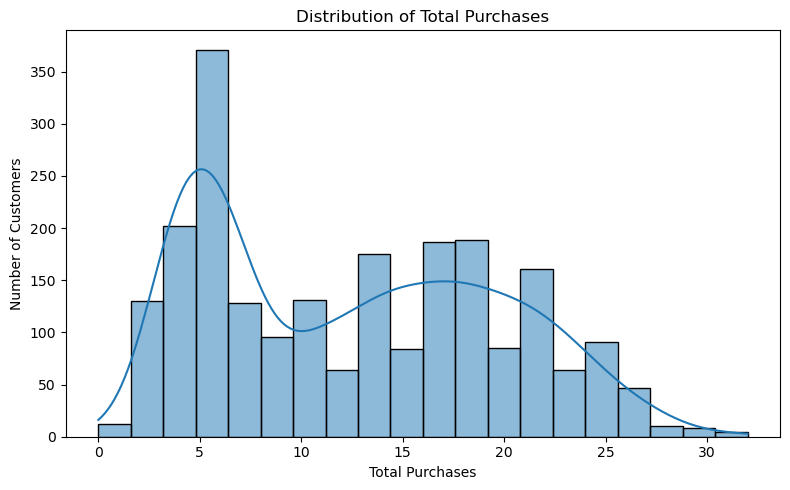

In [26]:
# Plot the distribution of TotalPurchases.
# This chart shows how frequently customers make purchases across channels.

plt.figure(figsize=(8, 5))
sns.histplot(df["TotalPurchases"], bins=20, kde=True)
plt.title("Distribution of Total Purchases")
plt.xlabel("Total Purchases")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


### Feature Engineering: Household Information

Create a **Children** feature by combining the number of kids and teenagers in the household.


In [27]:
# Calculate the total number of children in the customer's household.
# Kidhome and Teenhome are added together.

df["Children"] = (df["Kidhome"] + df["Teenhome"])

In [28]:
# Display the newly created Children feature.

df["Children"]

0       0
1       2
2       0
3       1
4       1
       ..
2235    1
2236    3
2237    0
2238    1
2239    2
Name: Children, Length: 2240, dtype: int64

### Feature Engineering: Campaign Response

Create **TotalCampaignAccepted** to summarize the customer's accepted marketing campaigns.


In [29]:
# List campaign-response columns.
# Sum them to measure the customer's total number of accepted campaigns/responses.

campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

df["TotalCampaignAccepted"] = (
    df[campaign_columns].sum(axis=1)
)

In [30]:
# Display TotalCampaignAccepted for all customers.

df["TotalCampaignAccepted"]

0       1
1       0
2       0
3       0
4       0
       ..
2235    0
2236    1
2237    1
2238    0
2239    1
Name: TotalCampaignAccepted, Length: 2240, dtype: int64

## 5. Selecting Features for Customer Segmentation

The selected variables represent customer demographics, spending, purchasing behaviour, web activity, campaign response, and complaints.


In [31]:
# Select the numerical customer-behavior features that will be used for K-Means clustering.
# These features describe income, age, household, purchasing behavior, web activity, campaigns, and complaints.

features = [
    "Income",
    "Age",
    "Children",
    "Recency",
    "TotalSpend",
    "TotalPurchases",
    "NumDealsPurchases",
    "NumWebVisitsMonth",
    "TotalCampaignAccepted",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "Complain"
]

In [32]:
# Check again for missing values in the DataFrame before modeling.

df.isnull().sum()

ID                       0
Year_Birth               0
Education                0
Marital_Status           0
Income                   0
Kidhome                  0
Teenhome                 0
Dt_Customer              0
Recency                  0
MntWines                 0
MntFruits                0
MntMeatProducts          0
MntFishProducts          0
MntSweetProducts         0
MntGoldProds             0
NumDealsPurchases        0
NumWebPurchases          0
NumCatalogPurchases      0
NumStorePurchases        0
NumWebVisitsMonth        0
AcceptedCmp3             0
AcceptedCmp4             0
AcceptedCmp5             0
AcceptedCmp1             0
AcceptedCmp2             0
Complain                 0
Response                 0
Age                      0
TotalSpend               0
TotalPurchases           0
Children                 0
TotalCampaignAccepted    0
dtype: int64

## 6. Outlier Detection and Treatment

Boxplots are used to identify extreme values. The notebook then applies IQR-based capping instead of deleting customer records.


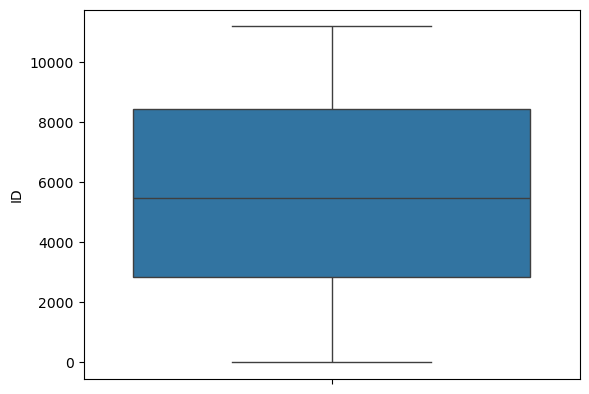

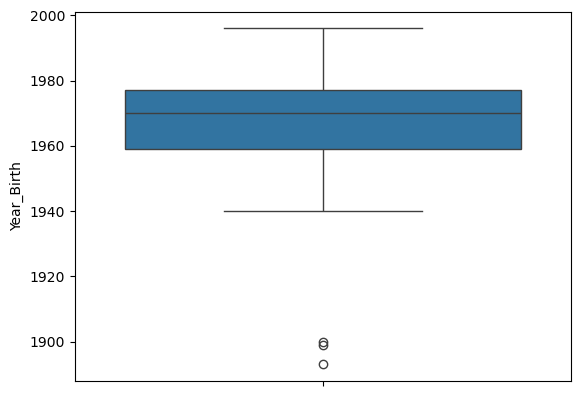

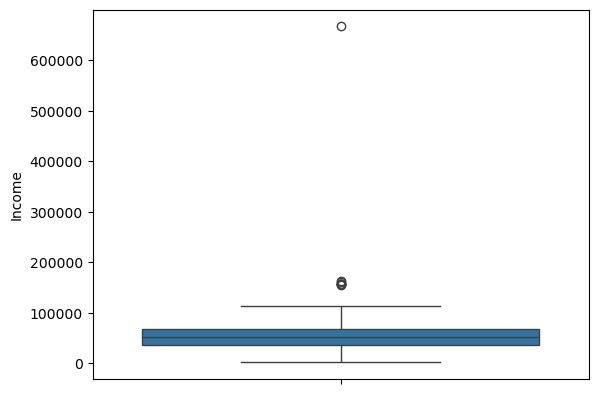

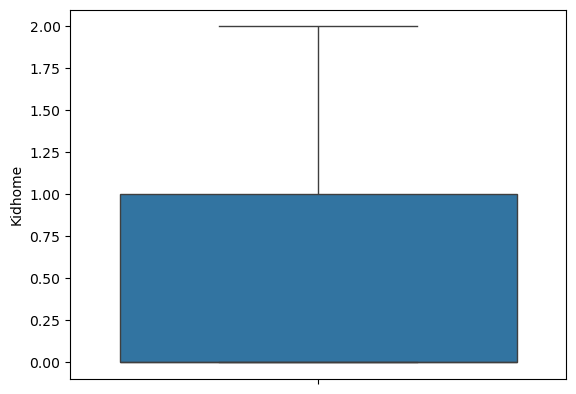

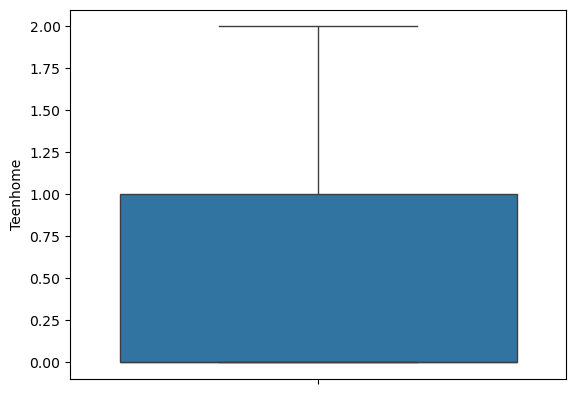

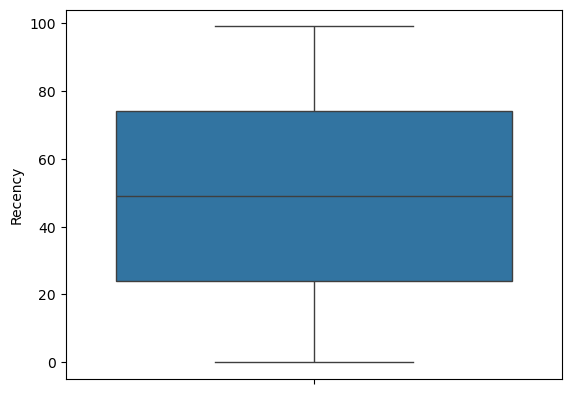

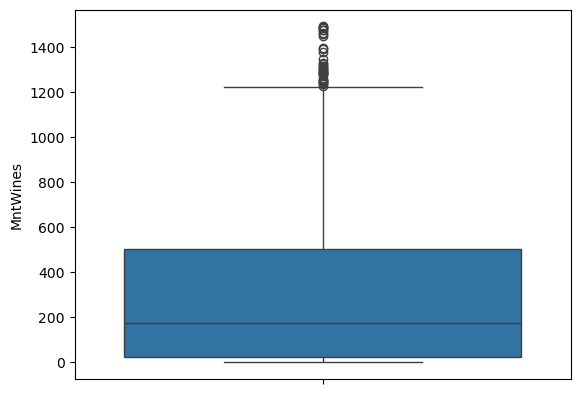

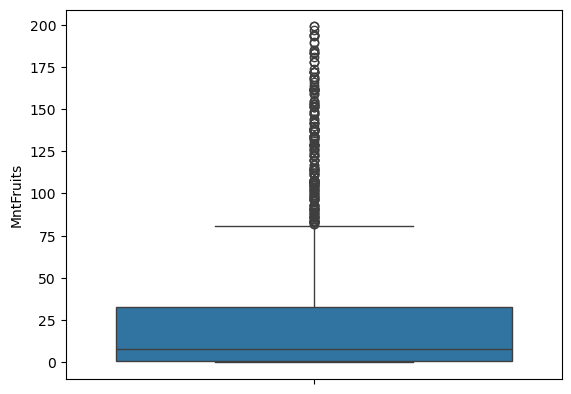

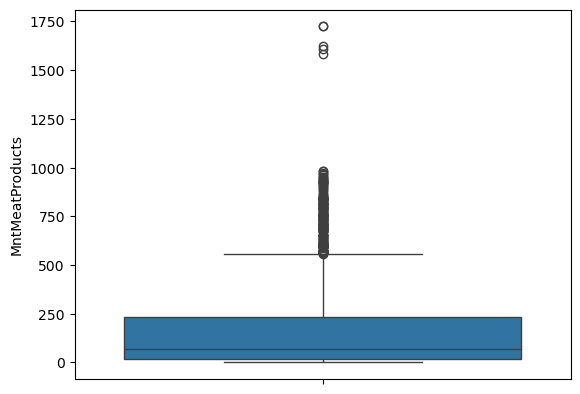

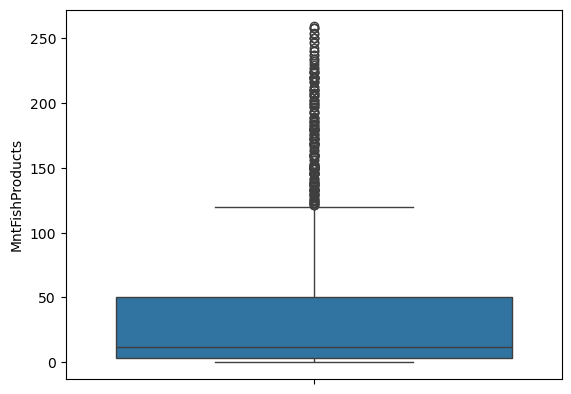

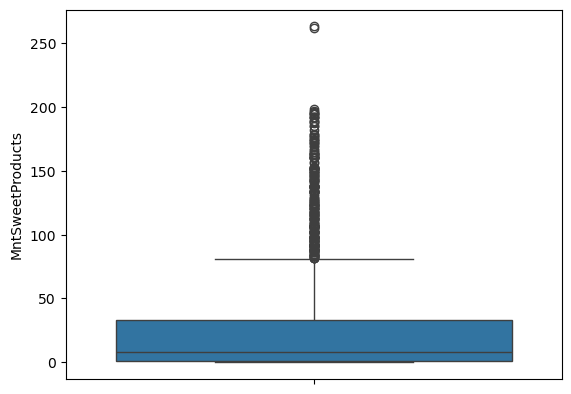

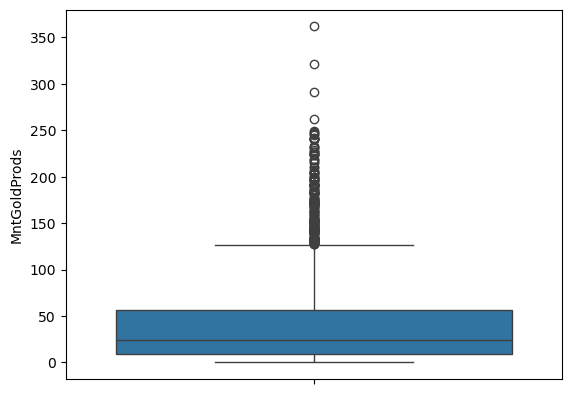

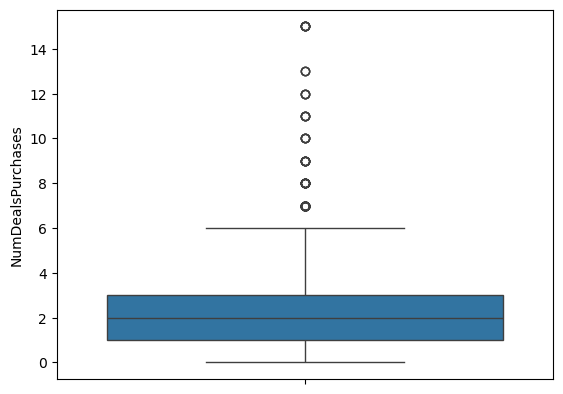

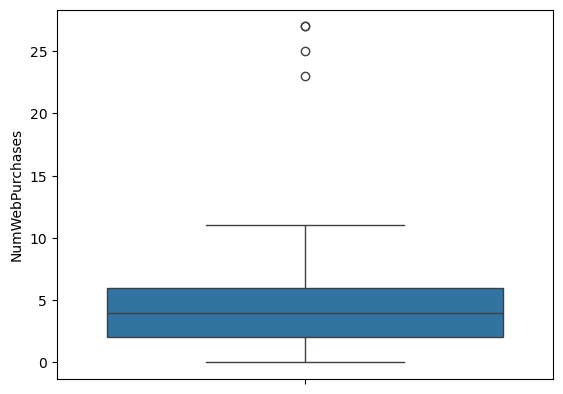

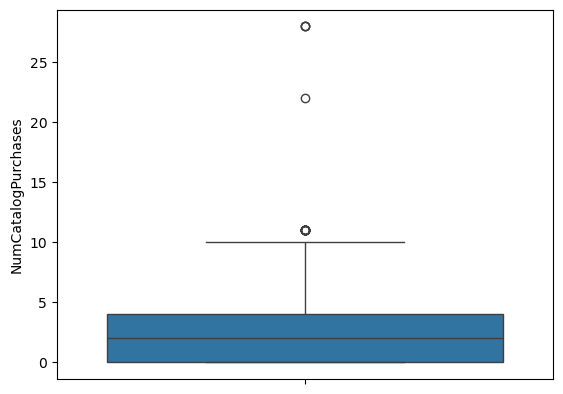

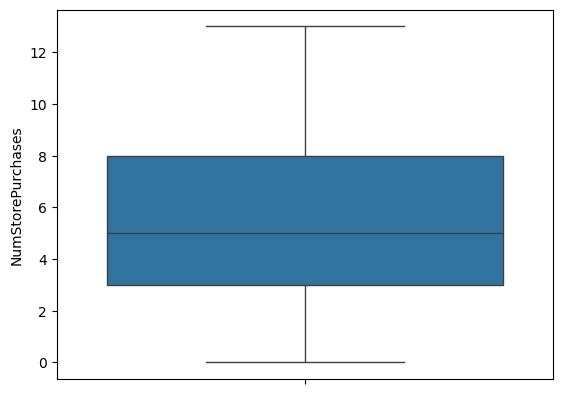

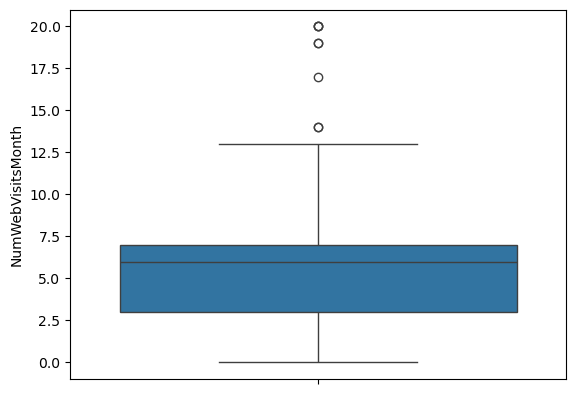

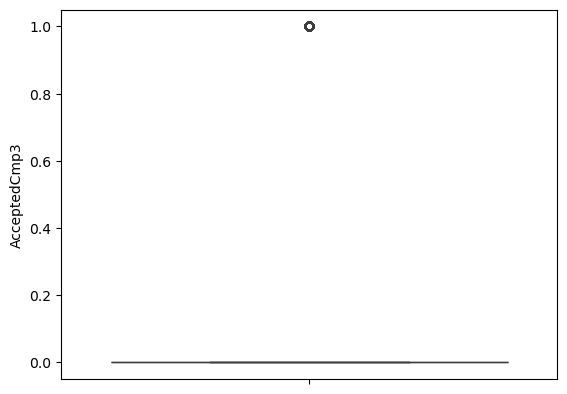

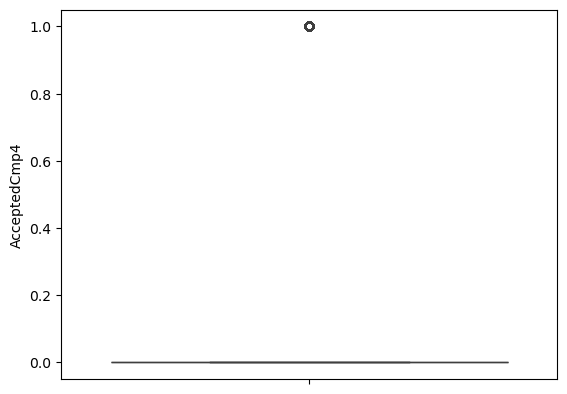

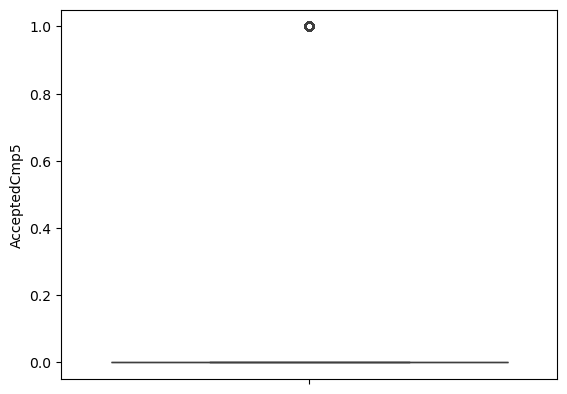

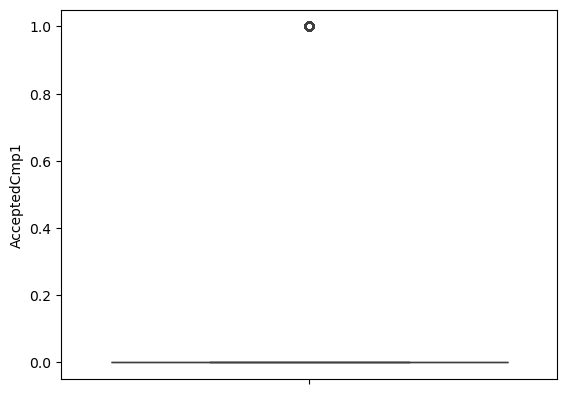

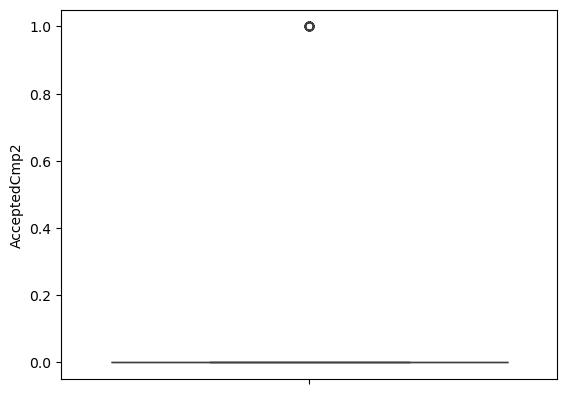

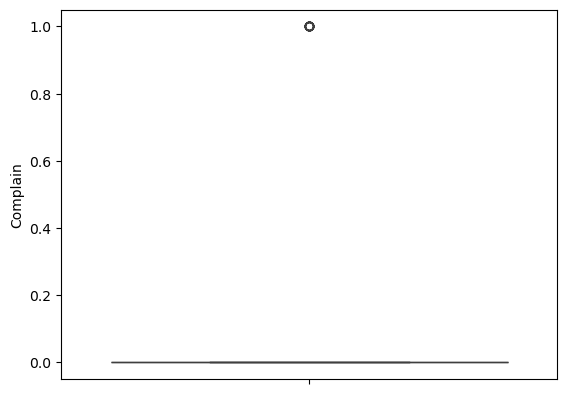

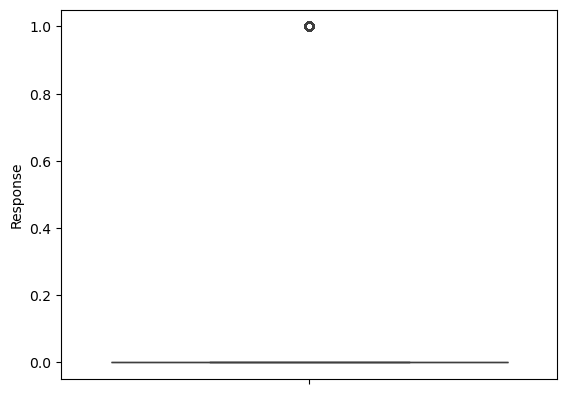

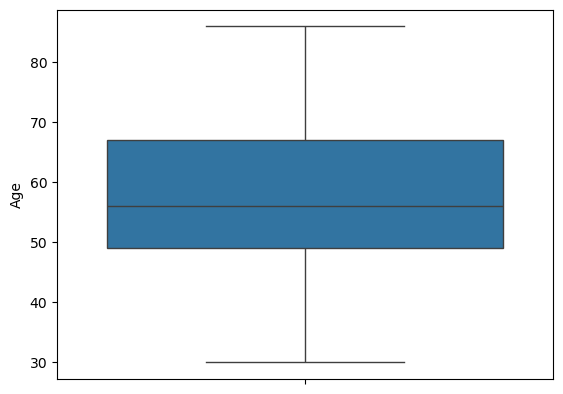

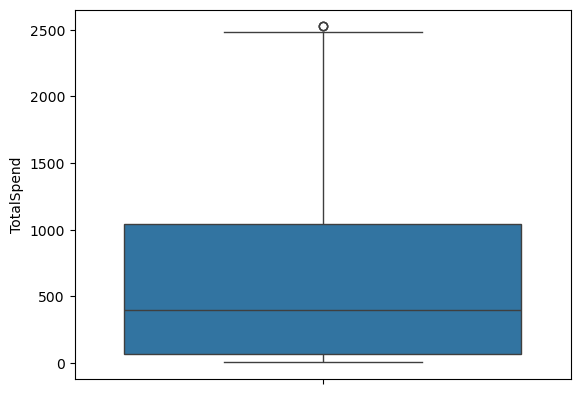

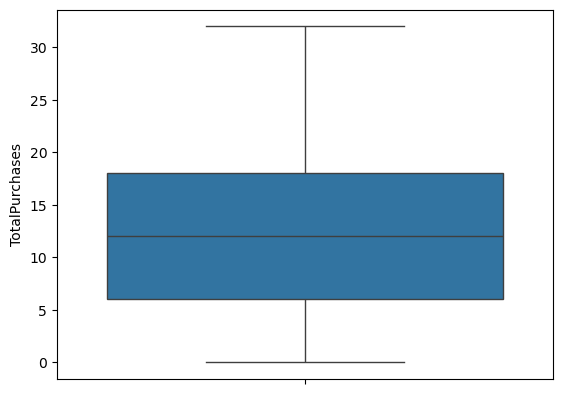

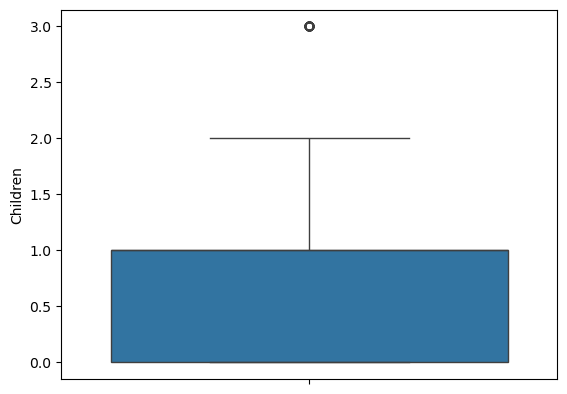

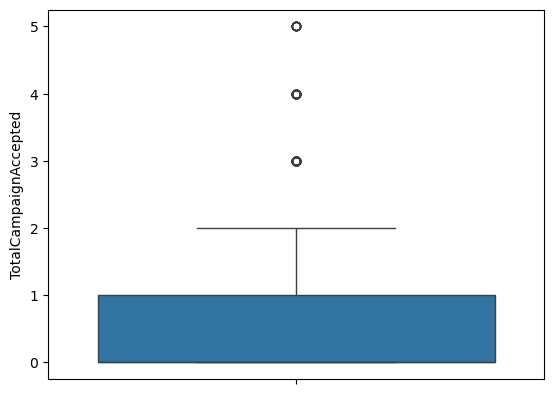

In [33]:
# Create a boxplot for every numerical column.
# Boxplots help visually identify potential outliers.

for i in df.select_dtypes(include=['int64', 'float64']).columns:
    sns.boxplot(df[i])
    plt.show()

In [34]:
# Apply IQR-based outlier capping to numerical columns.
# Q1 is the 25th percentile and Q3 is the 75th percentile.
# IQR must be calculated as Q3 - Q1.
# The lower and upper bounds are Q1 - 1.5*IQR and Q3 + 1.5*IQR.
for i in df.select_dtypes(include=['int64', 'float64']).columns:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    IQR = q3 - q1
    LB = q1 - 1.5 * IQR
    UB = q3 + 1.5 * IQR

    # Cap values outside the valid range instead of deleting the rows.
    df[i] = df[i].clip(LB, UB)

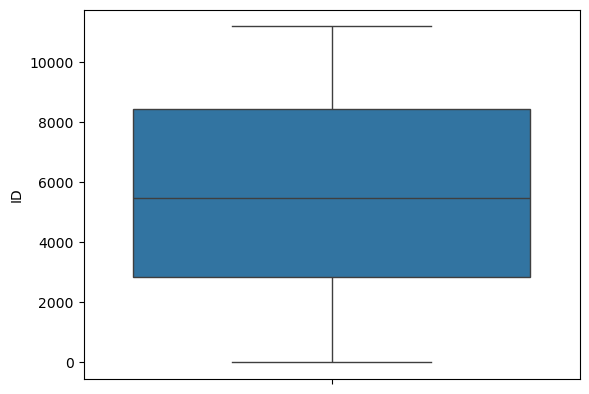

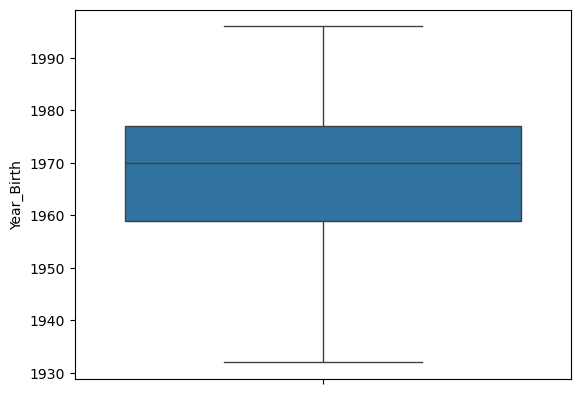

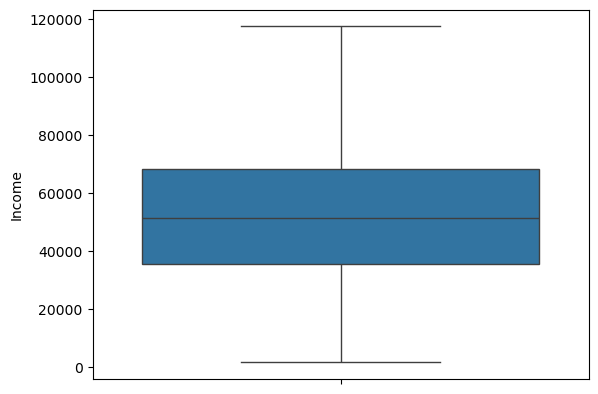

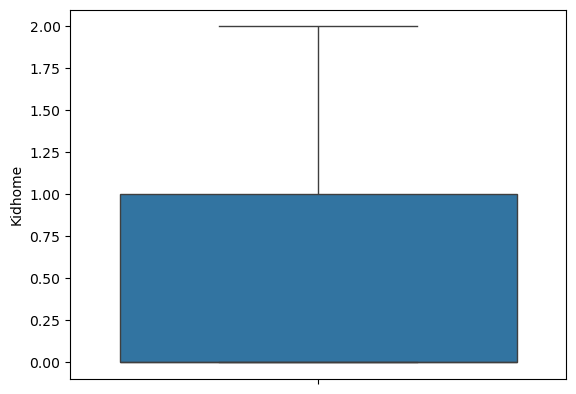

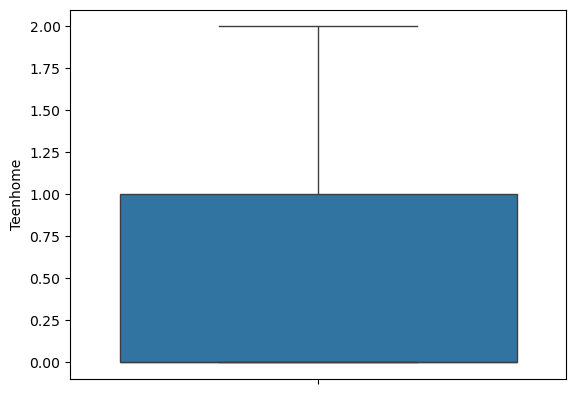

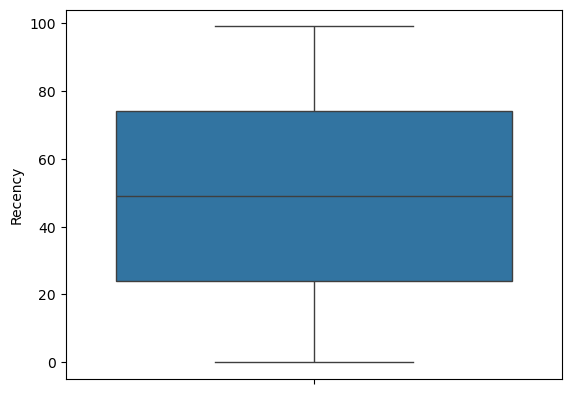

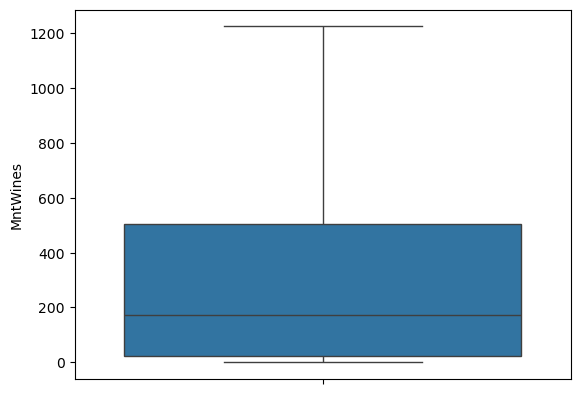

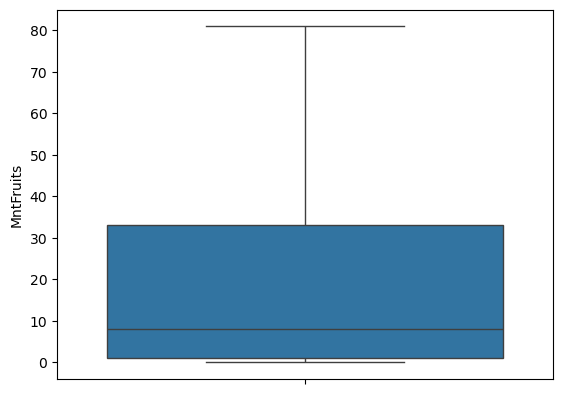

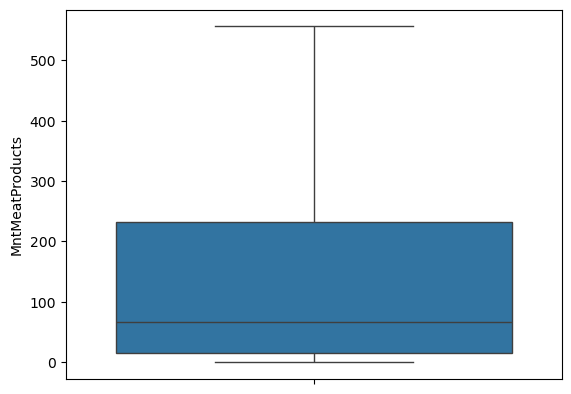

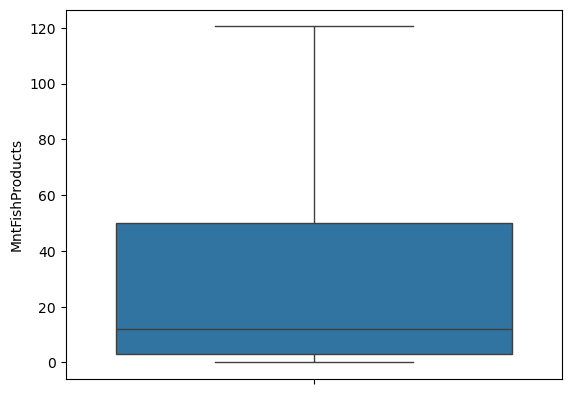

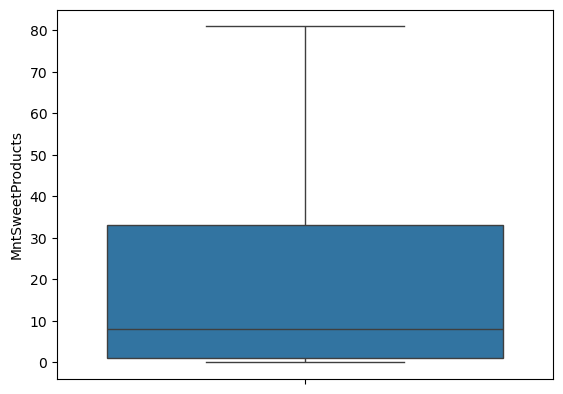

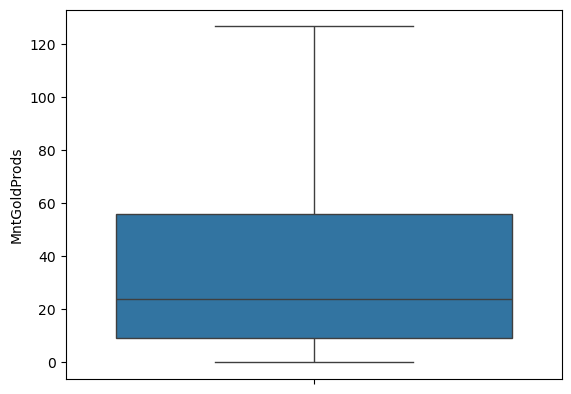

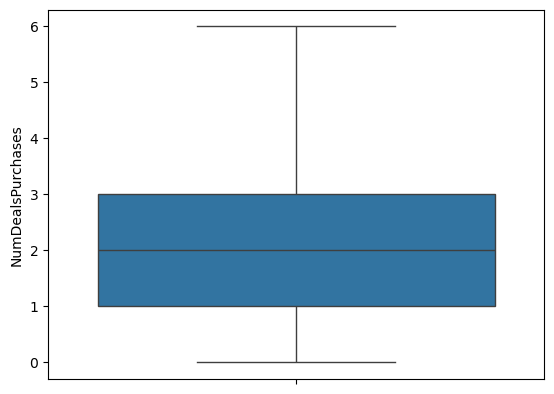

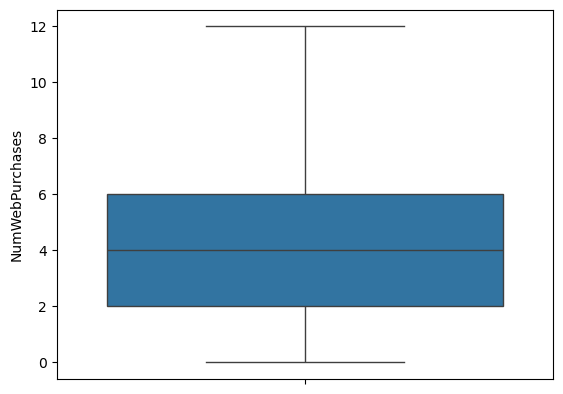

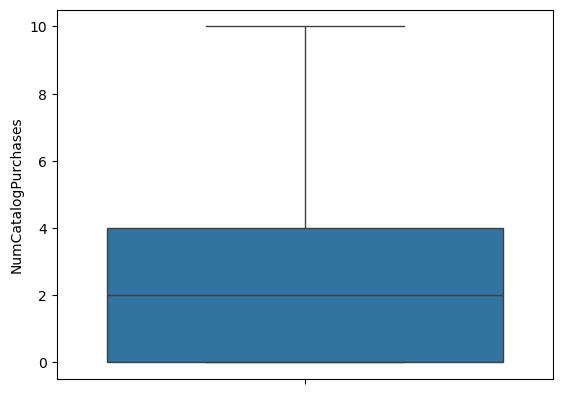

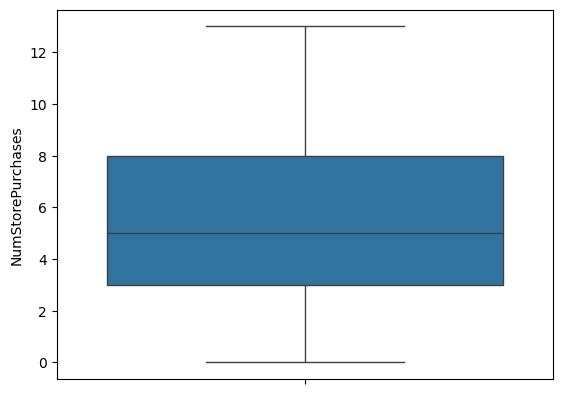

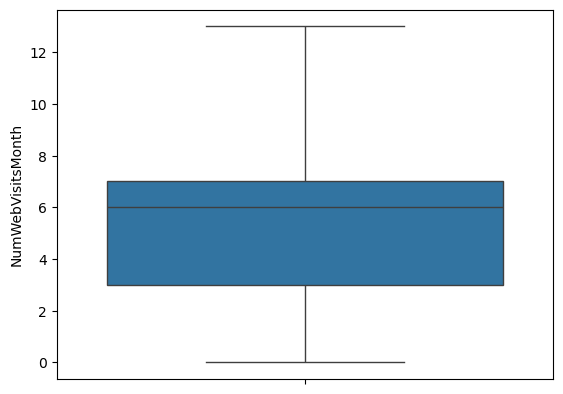

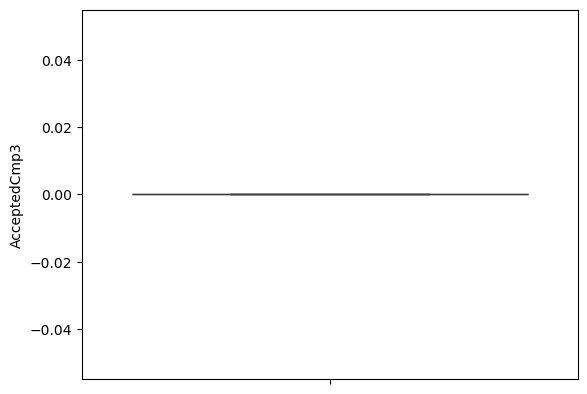

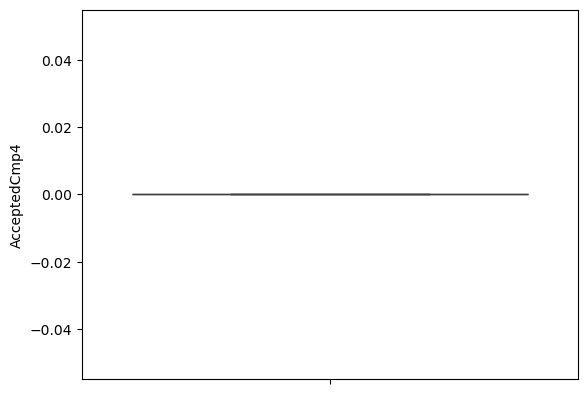

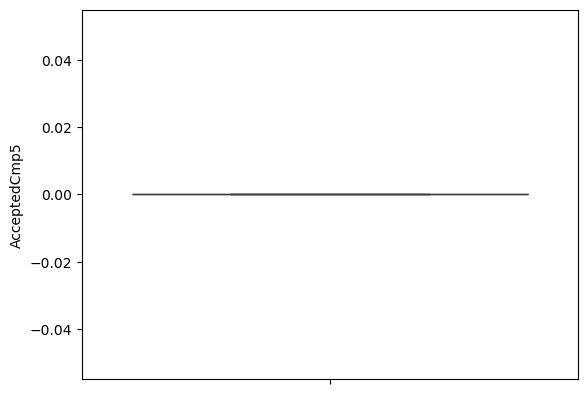

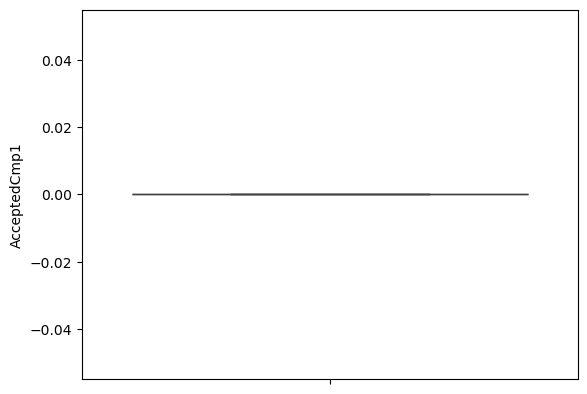

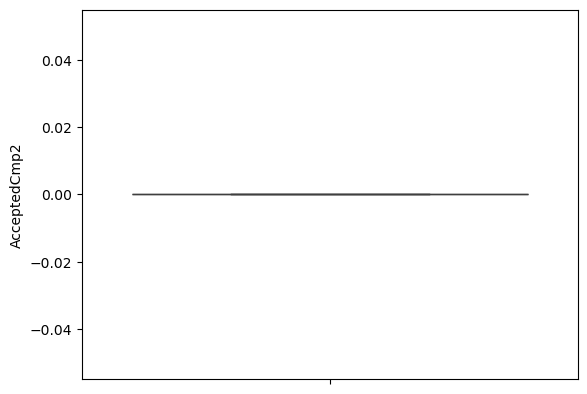

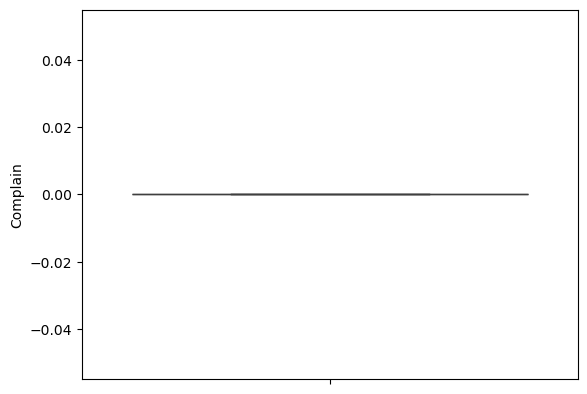

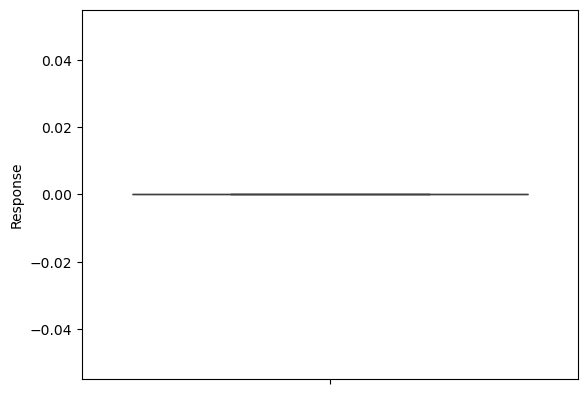

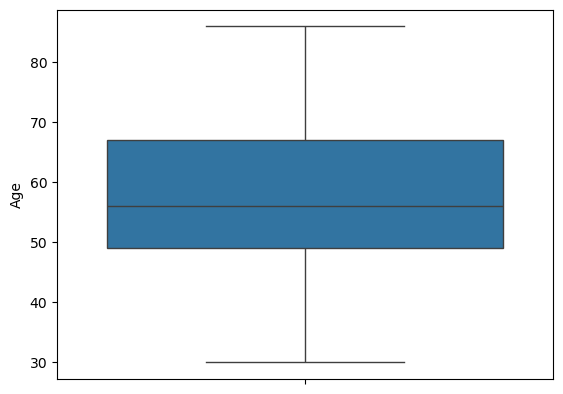

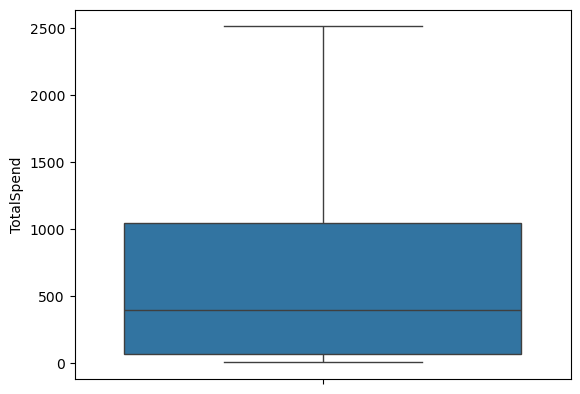

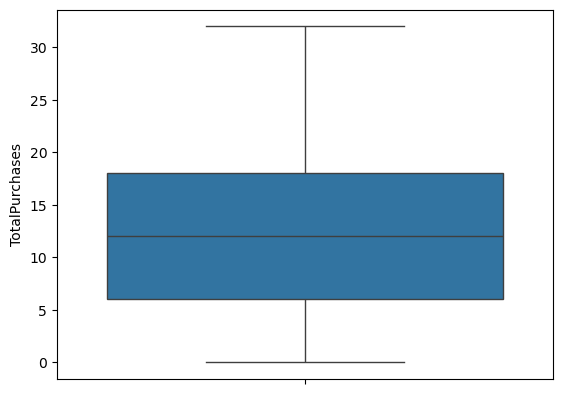

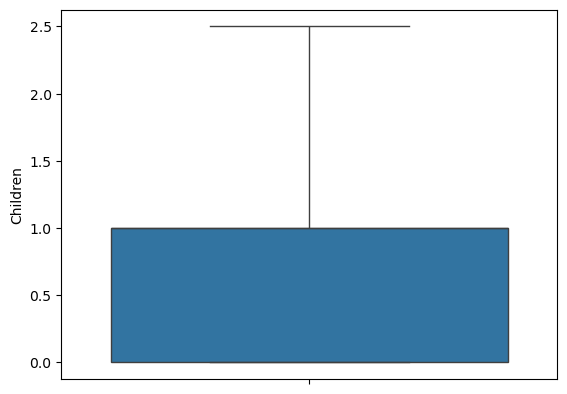

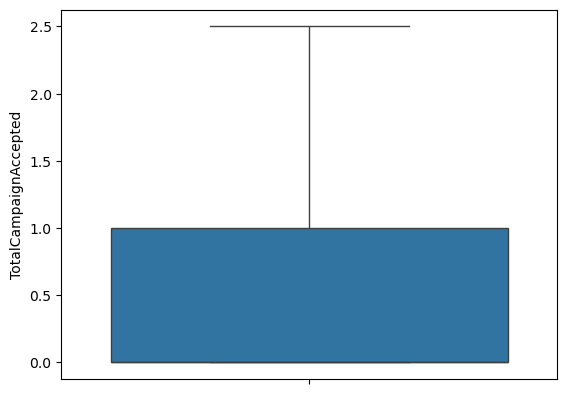

In [35]:
# Plot the numerical columns again after outlier capping.
# This allows us to visually check the effect of the treatment.

for i in df.select_dtypes(include=['int64', 'float64']).columns:
    sns.boxplot(df[i])
    plt.show()

## 7. Feature Scaling

Standardization ensures that features with different numerical ranges contribute more comparably to K-Means distance calculations.


In [36]:
# Standardize the clustering features so they have comparable scales.
# StandardScaler transforms each feature to approximately mean 0 and standard deviation 1.

from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
df[features] = sc.fit_transform(df[features])

In [37]:
# Display the standardized features that will be used for clustering.

df[features]

,Income,Age,Children,Recency,TotalSpend,TotalPurchases,NumDealsPurchases,NumWebVisitsMonth,TotalCampaignAccepted,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Complain
0,0.299651,1.018098,-1.298836,0.307039,1.679615,1.313544,0.509888,0.724452,0.824465,1.488353,2.697675,-0.550785,0.0
1,-0.263808,1.274694,1.468720,-0.383664,-0.961340,-1.185022,-0.140168,-0.127397,-0.550155,-1.156408,-0.594004,-1.166125,0.0
2,0.943420,0.333842,-1.298836,-0.798086,0.282733,1.035926,-0.790225,-0.553322,-0.550155,1.488353,-0.228262,1.295237,0.0
3,-1.204881,-1.291266,0.084942,-0.798086,-0.918154,-0.907403,-0.140168,0.298528,-0.550155,-0.778585,-0.959746,-0.550785,0.0
4,0.307056,-1.034670,0.084942,1.550305,-0.305253,0.203070,1.810001,-0.127397,-0.550155,0.354884,0.137480,0.064556,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,0.447037,0.162778,0.084942,-0.107383,1.221185,0.480689,-0.140168,-0.127397,-0.550155,1.866176,0.137480,-0.550785,0.0
2236,0.580377,1.958950,2.160609,0.237969,-0.268712,0.341880,2.460058,0.724452,0.824465,1.488353,-0.228262,-0.243114,0.0
2237,0.244375,-1.034670,-1.298836,1.446700,1.055087,0.758307,-0.790225,0.298528,0.824465,-0.778585,0.137480,2.218248,0.0
2238,0.830288,1.103630,0.084942,-1.419719,0.394018,1.174735,-0.140168,-0.979246,-0.550155,0.732707,0.868964,1.295237,0.0


## 8. Choosing the Number of Clusters

Test multiple values of **K** and compare inertia and silhouette score before building the final clustering model.


In [38]:
# Import K-Means clustering and the silhouette score metric.
# Inertia measures within-cluster variation; lower is generally better.
# Silhouette score measures how well-separated the clusters are; higher is generally better.
# Test K values from 2 through 8 to compare possible cluster counts.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

for k in range(2, 9):

    model = KMeans(n_clusters=k,random_state=42,n_init=20)

    labels = model.fit_predict(df[features])

    inertia.append(model.inertia_)

    score = silhouette_score(df[features],labels)

    silhouette_scores.append(score)

In [39]:
# Store the K, inertia, and silhouette score values in a DataFrame for easy comparison.

results = pd.DataFrame({
    "K": range(2, 9),
    "Inertia": inertia,
    "Silhouette": silhouette_scores
})

results

,K,Inertia,Silhouette
0,2,17547.622916,0.313580
1,3,14922.297630,0.255486
2,4,13835.422369,0.235557
3,5,12933.910292,0.155546
4,6,12152.855027,0.155643
5,7,11541.222987,0.162939
6,8,11083.572834,0.149609


### Model Selection Results

The table below compares the candidate cluster counts.  
- **Inertia:** lower values indicate less within-cluster variation.
- **Silhouette Score:** higher values indicate better separation between clusters.

These metrics should be considered together when selecting the final number of clusters.


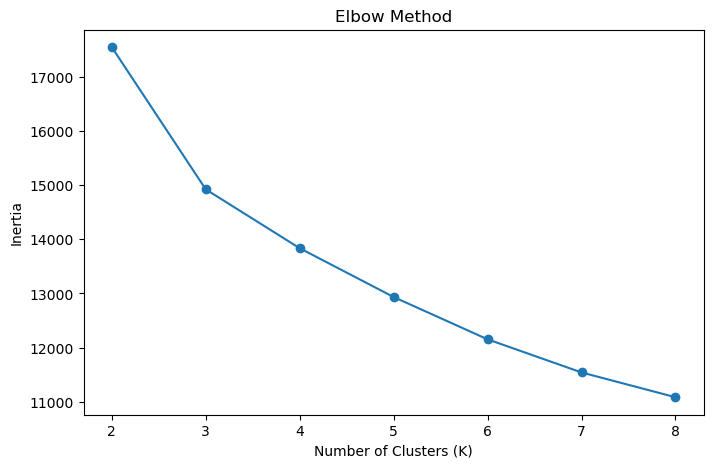

In [40]:
# Plot inertia against the number of clusters.
# The elbow point is used as one piece of evidence when selecting K.

plt.figure(figsize=(8,5))

plt.plot(
    results["K"],
    results["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

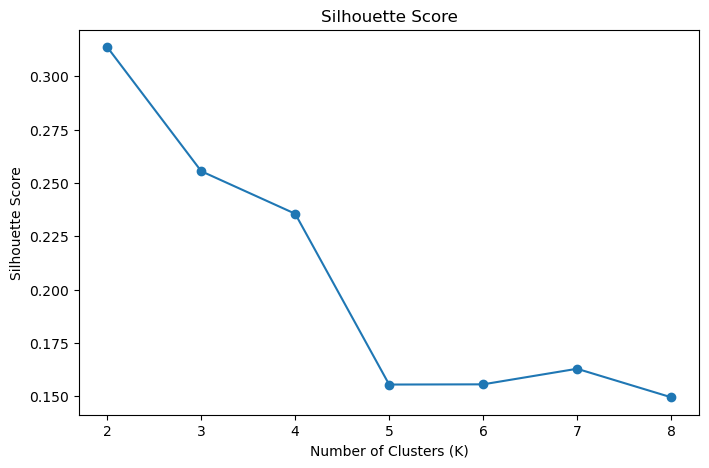

In [41]:
# Plot silhouette score against the number of clusters.
# Compare the scores to understand cluster separation for different K values.

plt.figure(figsize=(8,5))

plt.plot(
    results["K"],
    results["Silhouette"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")

plt.show()

# PART B — FIVE MODEL BUILDING AND MODEL EVALUATION

## 9. Five Model Building

This is the main **Model Building** section of the project. The same standardized customer features (`X_model`) are used for all five algorithms so their results can be compared fairly.

### Five models used
1. **Model 1 — K-Means Clustering**
2. **Model 2 — Agglomerative Hierarchical Clustering**
3. **Model 3 — Gaussian Mixture Model (GMM)**
4. **Model 4 — BIRCH Clustering**
5. **Model 5 — DBSCAN**

Each subsection contains: **model definition → fitting/training → cluster prediction → cluster-count output**.

After all five models are built, **Section 10** evaluates all five using the same clustering-quality metrics.


In [42]:
# Import the five clustering algorithms that will be compared.
# KMeans, AgglomerativeClustering, and DBSCAN come from sklearn.cluster.
# GaussianMixture is a probabilistic clustering algorithm from sklearn.mixture.
# BIRCH is useful for hierarchical/large-scale clustering.

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch
from sklearn.mixture import GaussianMixture

# Import three internal clustering evaluation metrics.
# These metrics do not require true class labels, which makes them suitable
# for an unsupervised customer segmentation problem.
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Create a clean modeling matrix from the already standardized features.
X_model = df[features].copy()

print("Modeling data shape:", X_model.shape)
X_model.head()


Modeling data shape: (2240, 13)


,Income,Age,Children,Recency,TotalSpend,TotalPurchases,NumDealsPurchases,NumWebVisitsMonth,TotalCampaignAccepted,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Complain
0,0.299651,1.018098,-1.298836,0.307039,1.679615,1.313544,0.509888,0.724452,0.824465,1.488353,2.697675,-0.550785,0.0
1,-0.263808,1.274694,1.468720,-0.383664,-0.961340,-1.185022,-0.140168,-0.127397,-0.550155,-1.156408,-0.594004,-1.166125,0.0
2,0.943420,0.333842,-1.298836,-0.798086,0.282733,1.035926,-0.790225,-0.553322,-0.550155,1.488353,-0.228262,1.295237,0.0
3,-1.204881,-1.291266,0.084942,-0.798086,-0.918154,-0.907403,-0.140168,0.298528,-0.550155,-0.778585,-0.959746,-0.550785,0.0
4,0.307056,-1.034670,0.084942,1.550305,-0.305253,0.203070,1.810001,-0.127397,-0.550155,0.354884,0.137480,0.064556,0.0


## 9.1 MODEL 1 OF 5 — K-Means Clustering

**Purpose:** Divide customers into 3 groups by minimizing within-cluster distance to centroids.

**What happens in the code below:**
- Create `KMeans(n_clusters=3)`.
- Fit the model on standardized customer features.
- Predict a cluster label for every customer.
- Store labels in `kmeans_labels` for later evaluation.


In [43]:
# MODEL 1: K-MEANS
# n_clusters=3 uses the cluster count selected earlier in the notebook.
# random_state=42 makes the result reproducible.
# n_init=20 runs the algorithm with multiple centroid initializations and
# keeps the best solution, reducing the chance of a poor random start.

kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=20)
kmeans_labels = kmeans_model.fit_predict(X_model)

# Display the number of customers assigned to each K-Means cluster.
pd.Series(kmeans_labels, name="KMeans_Cluster").value_counts().sort_index()


KMeans_Cluster
0     605
1    1011
2     624
Name: count, dtype: int64

## 9.2 MODEL 2 OF 5 — Agglomerative Hierarchical Clustering

**Purpose:** Build customer groups using a bottom-up hierarchical merging process.

**What happens in the code below:**
- Start with customers as separate observations.
- Use Ward linkage to merge similar groups while controlling within-cluster variance.
- Stop at 3 clusters for a fair comparison with K-Means.
- Store labels in `agg_labels` for later evaluation.


In [44]:
# MODEL 2: AGGLOMERATIVE CLUSTERING
# linkage="ward" merges clusters in a way that tries to minimize the increase
# in within-cluster variance. Ward linkage is appropriate for scaled numeric data.

agg_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
agg_labels = agg_model.fit_predict(X_model)

# Display the number of customers in each hierarchical cluster.
pd.Series(agg_labels, name="Agglomerative_Cluster").value_counts().sort_index()


Agglomerative_Cluster
0    879
1    836
2    525
Name: count, dtype: int64

## 9.3 MODEL 3 OF 5 — Gaussian Mixture Model (GMM)

**Purpose:** Create probabilistic customer segments by modeling the data as a mixture of Gaussian distributions.

**What happens in the code below:**
- Create a GMM with 3 components.
- Fit probability distributions to the standardized customer data.
- Assign each customer to the most likely component.
- Store labels in `gmm_labels` for later evaluation.


In [45]:
# MODEL 3: GAUSSIAN MIXTURE MODEL
# n_components=3 represents three customer segments.
# covariance_type="full" allows each component to have its own covariance shape.
# n_init=10 tries multiple initial solutions and keeps the best fit.

gmm_model = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=10
)
gmm_labels = gmm_model.fit_predict(X_model)

# Display the number of customers assigned to each GMM component.
pd.Series(gmm_labels, name="GMM_Cluster").value_counts().sort_index()


GMM_Cluster
0     226
1     612
2    1402
Name: count, dtype: int64

## 9.4 MODEL 4 OF 5 — BIRCH Clustering

**Purpose:** Create compact hierarchical summaries of the customer data and form final clusters efficiently.

**What happens in the code below:**
- Build BIRCH subclusters using `threshold=0.8`.
- Request 3 final clusters.
- Fit and predict customer groups.
- Store labels in `birch_labels` for later evaluation.


In [46]:
# MODEL 4: BIRCH
# threshold controls the radius of subclusters created by BIRCH.
# n_clusters=3 requests three final customer segments.

birch_model = Birch(threshold=0.8, n_clusters=3)
birch_labels = birch_model.fit_predict(X_model)

# Display the number of customers in each BIRCH cluster.
pd.Series(birch_labels, name="BIRCH_Cluster").value_counts().sort_index()


BIRCH_Cluster
0    792
1    491
2    957
Name: count, dtype: int64

## 9.5 MODEL 5 OF 5 — DBSCAN

**Purpose:** Find dense customer groups without fixing the number of clusters in advance and identify possible noise/outliers.

**What happens in the code below:**
- `eps=1.8` defines the neighborhood radius.
- `min_samples=10` defines the minimum density requirement.
- Fit DBSCAN and predict cluster labels.
- Label `-1` represents noise.
- Store labels in `dbscan_labels` for later evaluation.


In [47]:
# MODEL 5: DBSCAN
# Start with practical values for standardized multidimensional data.
# DBSCAN may create a different number of clusters than the other models
# and may label some observations as -1 (noise).

dbscan_model = DBSCAN(eps=1.8, min_samples=10)
dbscan_labels = dbscan_model.fit_predict(X_model)

# Display cluster/noise counts. A label of -1 represents noise.
dbscan_counts = pd.Series(dbscan_labels, name="DBSCAN_Cluster").value_counts().sort_index()
dbscan_counts


DBSCAN_Cluster
-1     369
 0    1871
Name: count, dtype: int64

# PART C — MODEL EVALUATION

## 10. Evaluation of All Five Models

Customer segmentation is an **unsupervised learning** problem, so there is no true target class. Therefore, classification metrics such as Accuracy, Precision, Recall, and F1-score are not suitable here.

We evaluate **all five models** with three internal clustering metrics:

1. **Silhouette Score — Higher is Better**  
   Measures how well each customer fits its own cluster compared with other clusters.

2. **Davies-Bouldin Index (DBI) — Lower is Better**  
   Measures cluster similarity; lower values indicate more compact and separated clusters.

3. **Calinski-Harabasz Index (CHI) — Higher is Better**  
   Compares between-cluster separation with within-cluster variation.

For DBSCAN, points labelled `-1` are treated as noise and excluded only while calculating these three internal quality metrics.


In [48]:
# Create a reusable evaluation function so that every model is measured
# using the same three metrics.

def evaluate_clustering(model_name, X, labels, ignore_noise=False):
    """Evaluate one clustering result using internal validation metrics."""

    X_eval = np.asarray(X)
    labels_eval = np.asarray(labels)
    noise_points = 0

    # DBSCAN can label observations as -1 (noise).
    # Exclude those observations only for the internal cluster-quality metrics.
    if ignore_noise:
        valid_mask = labels_eval != -1
        noise_points = int((~valid_mask).sum())
        X_eval = X_eval[valid_mask]
        labels_eval = labels_eval[valid_mask]

    unique_clusters = np.unique(labels_eval)
    n_clusters = len(unique_clusters)

    # Silhouette, DBI, and CHI need at least two clusters.
    # They also cannot be calculated if every observation forms its own cluster.
    if n_clusters < 2 or n_clusters >= len(labels_eval):
        return {
            "Model": model_name,
            "Clusters": n_clusters,
            "Noise Points": noise_points,
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    return {
        "Model": model_name,
        "Clusters": n_clusters,
        "Noise Points": noise_points,
        "Silhouette Score": silhouette_score(X_eval, labels_eval),
        "Davies-Bouldin Index": davies_bouldin_score(X_eval, labels_eval),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_eval, labels_eval)
    }

# Evaluate all five clustering models.
model_evaluation = pd.DataFrame([
    evaluate_clustering("K-Means", X_model, kmeans_labels),
    evaluate_clustering("Agglomerative", X_model, agg_labels),
    evaluate_clustering("Gaussian Mixture Model", X_model, gmm_labels),
    evaluate_clustering("BIRCH", X_model, birch_labels),
    evaluate_clustering("DBSCAN", X_model, dbscan_labels, ignore_noise=True)
])

# Round metric values to make the comparison table easier to read.
model_evaluation.round(4)


,Model,Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0,0.2555,1.5827,896.2889
1,Agglomerative,3,0,0.1958,1.7567,731.3294
2,Gaussian Mixture Model,3,0,0.1648,2.5388,348.0339
3,BIRCH,3,0,0.1880,1.9596,726.7660
4,DBSCAN,1,369,NaN,NaN,NaN


### 10.1 Five-Model Evaluation Table

The code above evaluates **every model built in Section 9**:

| Model No. | Model | Labels evaluated |
|---|---|---|
| 1 | K-Means | `kmeans_labels` |
| 2 | Agglomerative | `agg_labels` |
| 3 | Gaussian Mixture Model | `gmm_labels` |
| 4 | BIRCH | `birch_labels` |
| 5 | DBSCAN | `dbscan_labels` |

The resulting `model_evaluation` DataFrame places the **five models in one comparison table** with Clusters, Noise Points, Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.


### 10.2 Ranking the Five Models

No single metric tells the complete story. A strong clustering solution should ideally have:

- a **high Silhouette Score**,
- a **low Davies-Bouldin Index**, and
- a **high Calinski-Harabasz Index**.

The following code ranks the valid models by Silhouette Score as a simple primary comparison. The other two metrics should still be checked before making the final business decision.


In [49]:
# Rank models from highest to lowest Silhouette Score.
# dropna() prevents invalid DBSCAN configurations from being selected.
model_ranking = (
    model_evaluation
    .dropna(subset=["Silhouette Score"])
    .sort_values("Silhouette Score", ascending=False)
    .reset_index(drop=True)
)

model_ranking.round(4)


,Model,Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0,0.2555,1.5827,896.2889
1,Agglomerative,3,0,0.1958,1.7567,731.3294
2,BIRCH,3,0,0.1880,1.9596,726.7660
3,Gaussian Mixture Model,3,0,0.1648,2.5388,348.0339


### 10.3 Visual Comparison of Evaluation Metrics

The bar charts below make it easier to compare model performance. Remember that **Silhouette and Calinski-Harabasz should be maximized**, while the **Davies-Bouldin Index should be minimized**.


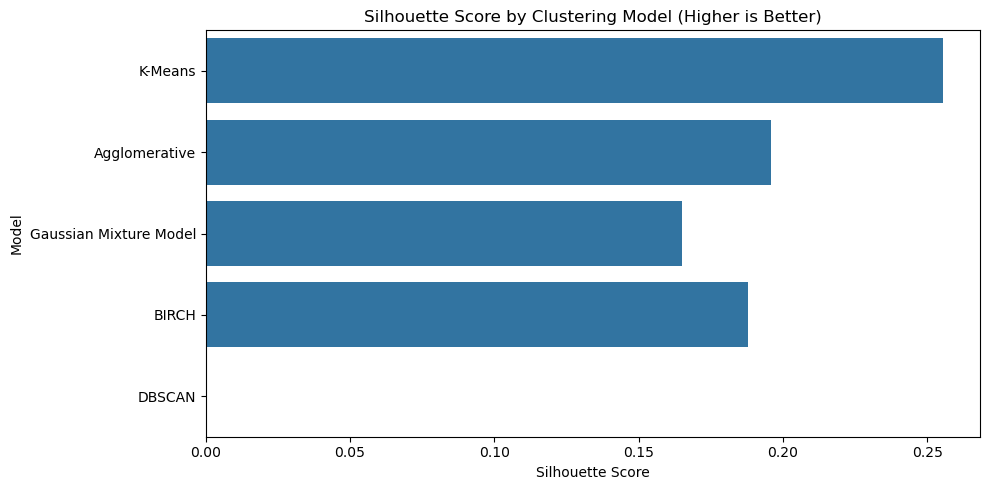

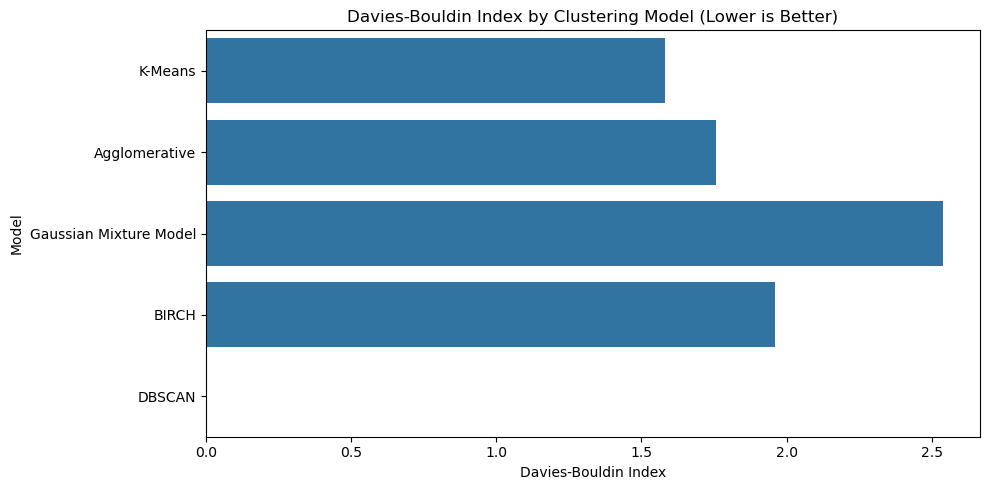

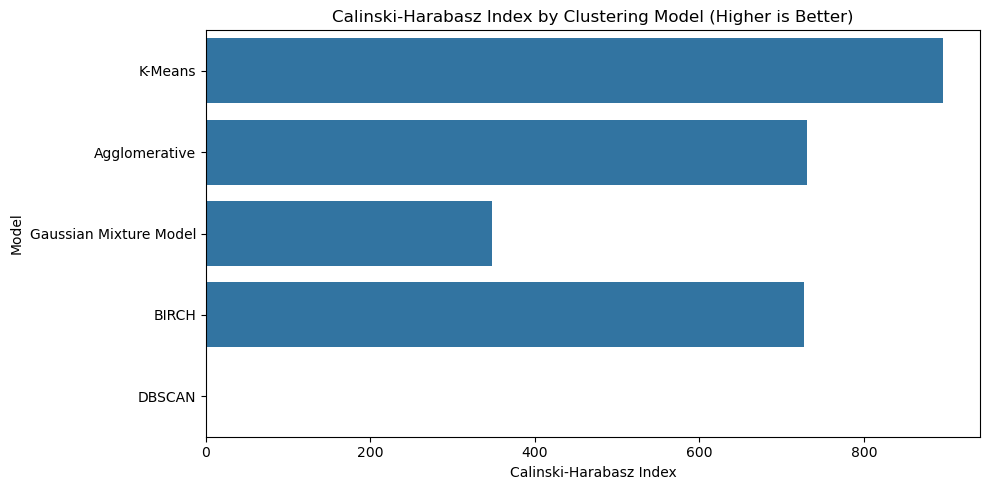

In [50]:
# Create separate bar charts because the three evaluation metrics have
# different numerical scales and different interpretation directions.

plt.figure(figsize=(10, 5))
sns.barplot(data=model_evaluation, x="Silhouette Score", y="Model")
plt.title("Silhouette Score by Clustering Model (Higher is Better)")
plt.xlabel("Silhouette Score")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=model_evaluation, x="Davies-Bouldin Index", y="Model")
plt.title("Davies-Bouldin Index by Clustering Model (Lower is Better)")
plt.xlabel("Davies-Bouldin Index")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=model_evaluation, x="Calinski-Harabasz Index", y="Model")
plt.title("Calinski-Harabasz Index by Clustering Model (Higher is Better)")
plt.xlabel("Calinski-Harabasz Index")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


### 10.4 Final Evaluation Interpretation

Use the comparison table and charts together rather than selecting a model from only one number.

- If a model has the **highest Silhouette Score**, it has the strongest average separation/cohesion according to that metric.
- If a model has the **lowest Davies-Bouldin Index**, its clusters are comparatively compact and distinct.
- If a model has the **highest Calinski-Harabasz Index**, it shows a strong ratio of between-cluster separation to within-cluster variation.
- For **DBSCAN**, also check `Noise Points`. A very large noise count may make the segmentation less useful for marketing, even when its metric values look good on the remaining observations.
- Statistical quality is important, but the final model should also create **stable, interpretable, and actionable customer segments** for the business.

For this ExcelR project, we continue with **K-Means (K=3)** for the final customer profiles because the notebook's earlier K-selection workflow was designed around K-Means and the resulting centroids/segments are straightforward to explain to business stakeholders. The five-model comparison above provides additional evidence and demonstrates that alternative clustering approaches were also evaluated.


## 11. Final K-Means Model

Create the final model with 3 clusters and assign a cluster label to every customer.


In [51]:
# Create the final K-Means model using 3 clusters.
# random_state makes the result reproducible and n_init runs multiple initializations.
# Add the predicted cluster label to each customer.

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

df["Cluster"] = kmeans.fit_predict(
    df[features]
)

In [52]:
# Count how many customers belong to each cluster.

df["Cluster"].value_counts().sort_index()

Cluster
0     605
1    1011
2     624
Name: count, dtype: int64

### Cluster Size Visualization

A bar chart makes it easier to compare the number of customers assigned to each cluster.


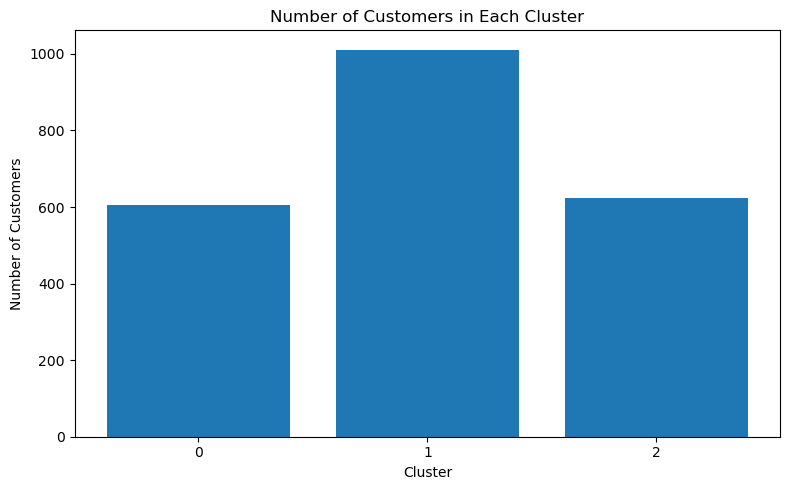

In [53]:
# Count customers in each cluster and visualize the cluster sizes.
# A bar chart is useful here because clusters are categorical groups.

cluster_counts = df["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [54]:
# Calculate the percentage of customers belonging to each cluster.

cluster_percentage = (
    df["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

cluster_percentage

Cluster
0    27.008929
1    45.133929
2    27.857143
Name: proportion, dtype: float64

## 12. Customer Segment Profiling

Calculate the average feature values for each cluster to understand the characteristics of the customer segments.


In [55]:
# Calculate the average value of each clustering feature for every cluster.
# This profile helps us understand the characteristics of each customer segment.

cluster_profile = df.groupby("Cluster")[features].mean()

cluster_profile.round(2)

,Income,Age,Children,Recency,TotalSpend,TotalPurchases,NumDealsPurchases,NumWebVisitsMonth,TotalCampaignAccepted,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Complain
Cluster,,,,,,,,,,,,,
0,1.14,0.09,-1.01,0.02,1.24,0.97,-0.68,-1.06,0.63,0.40,1.19,0.80,0.0
1,-0.82,-0.22,0.36,0.02,-0.85,-0.95,-0.21,0.45,-0.32,-0.78,-0.77,-0.81,0.0
2,0.22,0.26,0.40,-0.05,0.18,0.60,1.01,0.30,-0.09,0.87,0.10,0.54,0.0


### Segment Profile Comparison

The following bar chart compares the average values of the main clustering features across segments. It helps explain how customer groups differ.


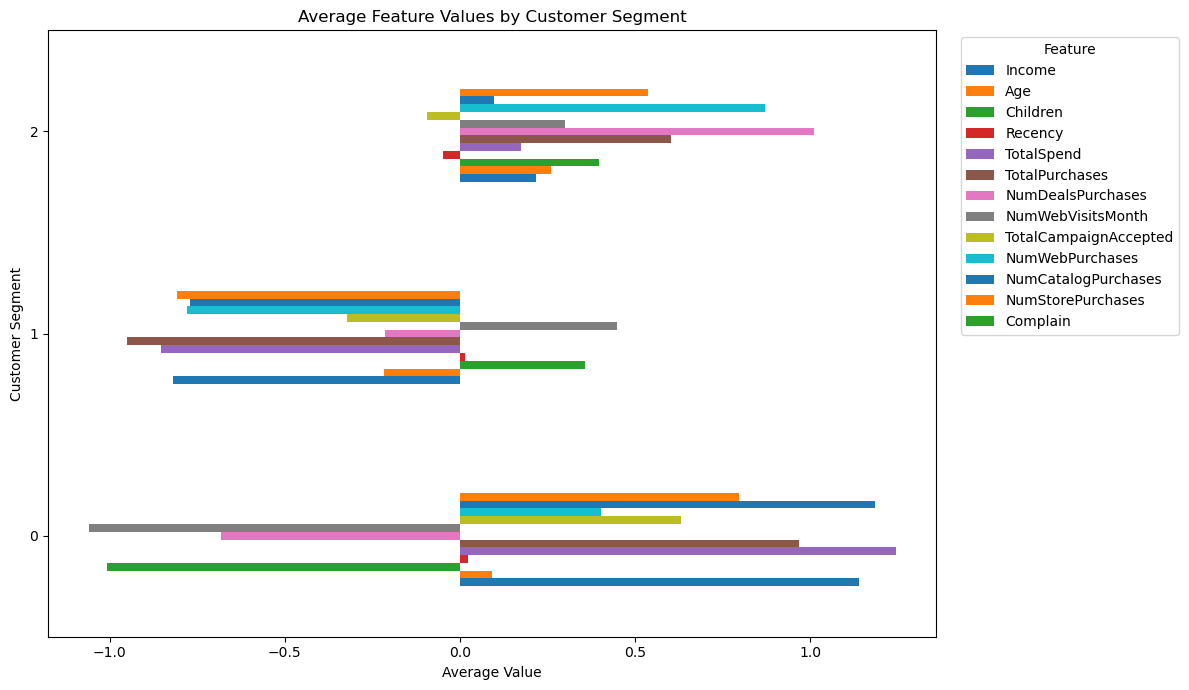

In [56]:
# Plot the average clustering features for each customer segment.
# A horizontal bar chart is useful because feature names can be long.

profile_for_plot = cluster_profile.copy()

ax = profile_for_plot.plot(kind="barh", figsize=(12, 7))
ax.set_title("Average Feature Values by Customer Segment")
ax.set_xlabel("Average Value")
ax.set_ylabel("Customer Segment")
plt.legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 13. PCA Visualization

Use Principal Component Analysis to project the high-dimensional customer data into two dimensions for visualization.


In [57]:
# Import PCA (Principal Component Analysis).
# Reduce the clustering feature space to two principal components for visualization.
# PCA is used here for visualization, not for creating the original cluster labels.

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(df[features])

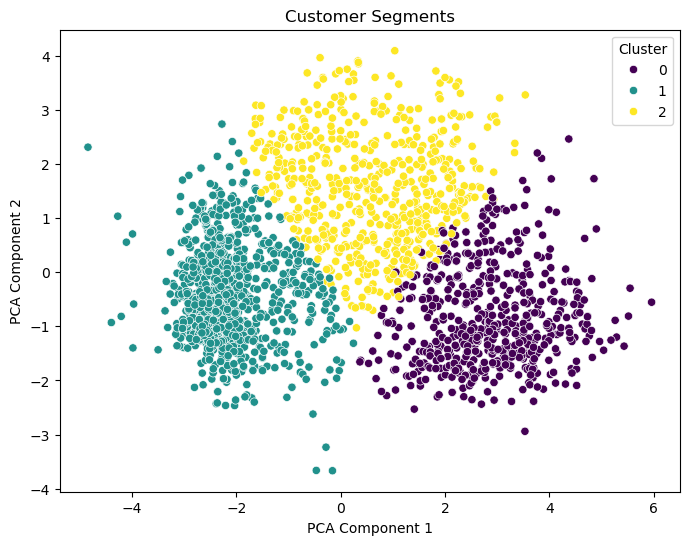

In [58]:
# Create a 2D scatter plot of the PCA-transformed customers.
# Color points according to their K-Means cluster to visually inspect the segments.

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=df["Cluster"],
    palette="viridis"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Customer Segments")

plt.show()

## 14. Export the Final Dataset

Save the cleaned dataset, engineered features, and final cluster labels to an Excel file.


In [59]:
# Save the final customer dataset, including engineered features and cluster labels, to an Excel file.

df.to_excel("customer_segmentation_result.xlsx",index=False)

### Visualization Summary

- **Histograms** show the distribution of numerical customer features.
- **Boxplots** help identify and review extreme values.
- **Elbow and Silhouette charts** support the choice of the number of clusters.
- **Bar charts** compare cluster sizes and average segment profiles.
- **PCA scatter plot** provides a visual view of customer separation in two dimensions.


## Conclusion

The workflow is now complete: the customer data was cleaned, transformed, segmented with K-Means, profiled, visualized, and exported.


In [60]:
# End of the customer segmentation workflow.



# 15. Deployment: Export Results to PKL and Streamlit

This section **does not change the original analysis**. Run the notebook from the beginning (Kernel → Restart & Run All), then run the next cell. It saves the five cluster assignments, evaluation metrics, standardized feature data, and PCA coordinates to `customer_segmentation.pkl`.

**Presentation explanation:** “I trained five clustering models in Jupyter Notebook, saved their outputs in a PKL file, and created a Streamlit dashboard to display the saved results without retraining the models.”

**Important:** The PKL stores the trained results for this dataset. It is not a general-purpose prediction API for new customers. Only load PKL files you created or trust.

In [61]:
# STEP 15.1: Export the results of all five trained clustering models.
# Run this cell only after completing the notebook's model training and PCA steps.
import pickle
import numpy as np
import pandas as pd

# Keep cluster labels from the models trained in Section 9.
cluster_labels = {
    "K-Means": np.asarray(kmeans_labels),
    "Agglomerative": np.asarray(agg_labels),
    "Gaussian Mixture Model": np.asarray(gmm_labels),
    "BIRCH": np.asarray(birch_labels),
    "DBSCAN": np.asarray(dbscan_labels),
}

# The notebook already standardized df[features] in Section 7.
# Save that exact matrix for consistent PCA and cluster visualizations.
feature_matrix = df[features].to_numpy(copy=True)

# Save all required dashboard data together in one PKL file.
# Note: df contains scaled clustering features because the notebook overwrites
# those columns during StandardScaler transformation in Section 7.
artifact = {
    "project": "ExcelR Customer Segmentation",
    "feature_names": list(features),
    "customers": df.copy().reset_index(drop=True),
    "X": feature_matrix,
    "labels": cluster_labels,
    "evaluation": model_evaluation.copy(),
    "pca_coordinates": np.asarray(X_pca).copy(),
}

# Validate that every model predicted one label per customer.
assert all(len(v) == len(df) for v in cluster_labels.values())
assert len(artifact["pca_coordinates"]) == len(df)

with open("customer_segmentation.pkl", "wb") as file:
    pickle.dump(artifact, file, protocol=pickle.HIGHEST_PROTOCOL)

print("Saved customer_segmentation.pkl successfully!")
print("Customers:", len(df))
print("Models:", ", ".join(cluster_labels))
print("Next: run 'streamlit run app.py' in the project folder.")


Saved customer_segmentation.pkl successfully!
Customers: 2240
Models: K-Means, Agglomerative, Gaussian Mixture Model, BIRCH, DBSCAN
Next: run 'streamlit run app.py' in the project folder.
